# 00 · EDA y preprocesamiento
**Caso:** predicción de churn en un banco · Métodos de Analítica II

Objetivo: estimar la probabilidad de que cada cliente abandone el banco para priorizar el programa de beneficios.

In [1]:
# La instalación de librerías solo se hace una vez (primera vez). Quite el # para instalar.
#%pip install pandas numpy matplotlib seaborn scikit-learn openpyxl
#%pip install tensorflow scikeras

In [2]:
# Librerías base
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Funciones compartidas del proyecto (métricas, gráficas, rutas) -> archivo churn_utils.py
from churn_utils import *

pd.options.display.max_columns = None
plt.rcParams["figure.dpi"] = 100

import seaborn as sns
from sklearn.model_selection import train_test_split

## 1. Carga de datos

In [3]:
df = pd.read_excel(RUTA_DATOS_CRUDOS)   # data/bank_churn.xlsx
print(df.shape)
df.head()

(10127, 21)


,clientnum,attrition_flag,customer_age,gender,dependent_count,education_level,marital_status,income_category,card_category,months_on_book,total_relationship_count,months_inactive_12_mon,contacts_count_12_mon,credit_limit,total_revolving_bal,avg_open_to_buy,total_amt_chng_q4_q1,total_trans_amt,total_trans_ct,total_ct_chng_q4_q1,avg_utilization_ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   clientnum                 10127 non-null  int64  
 1   attrition_flag            10127 non-null  str    
 2   customer_age              10127 non-null  int64  
 3   gender                    10127 non-null  str    
 4   dependent_count           10127 non-null  int64  
 5   education_level           10127 non-null  str    
 6   marital_status            10127 non-null  str    
 7   income_category           10127 non-null  str    
 8   card_category             10127 non-null  str    
 9   months_on_book            10127 non-null  int64  
 10  total_relationship_count  10127 non-null  int64  
 11  months_inactive_12_mon    10127 non-null  int64  
 12  contacts_count_12_mon     10127 non-null  int64  
 13  credit_limit              10127 non-null  float64
 14  total_revolving_b

In [5]:
# Revisar datos faltantes y duplicados
print("Faltantes por columna:\n", df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().sum() > 0 else "No hay valores NaN")
print("\nClientes duplicados:", df.duplicated("clientnum").sum())

Faltantes por columna:
 No hay valores NaN

Clientes duplicados: 0


* 10.127 clientes, 21 variables, sin nulos ni duplicados.
* Hay faltantes como `Unknown`: se dejan como categoría propia.

In [6]:
# ¿Cuántos 'Unknown' hay? (faltantes disfrazados)
for col in ["education_level", "marital_status", "income_category"]:
    print(f"{col:<16}: {(df[col] == 'Unknown').sum():>5} ({(df[col] == 'Unknown').mean():.1%})")

education_level :  1519 (15.0%)
marital_status  :   749 (7.4%)
income_category :  1112 (11.0%)


## 2. Variable objetivo
`churn = 1` si el cliente se fue (Attrited Customer).

churn
0    8500
1    1627
Name: count, dtype: int64

Tasa de fuga: 16.07%


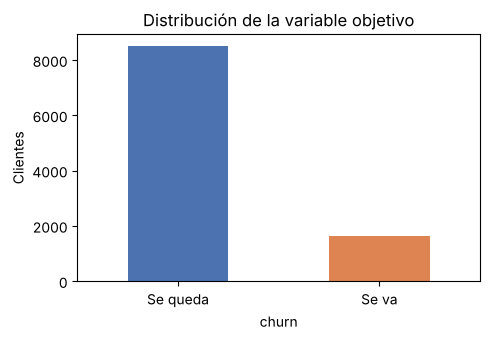

In [7]:
df["churn"] = np.where(df["attrition_flag"] == "Attrited Customer", 1, 0)
print(df["churn"].value_counts())
print("\nTasa de fuga: %.2f%%" % (100 * df["churn"].mean()))

ax = df["churn"].map({0: "Se queda", 1: "Se va"}).value_counts().plot(kind="bar", color=["#4C72B0", "#DD8452"], figsize=(5, 3.5))
ax.set_title("Distribución de la variable objetivo"); ax.set_ylabel("Clientes"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

* Solo ~16% se fue → base desbalanceada: usamos AUC y partición estratificada.

## 3. EDA
### 3.1 Variables numéricas

In [8]:
num_cols = ["customer_age", "dependent_count", "months_on_book", "total_relationship_count",
            "months_inactive_12_mon", "contacts_count_12_mon", "credit_limit", "total_revolving_bal",
            "avg_open_to_buy", "total_amt_chng_q4_q1", "total_trans_amt", "total_trans_ct",
            "total_ct_chng_q4_q1", "avg_utilization_ratio"]
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
customer_age,10127.0,46.33,8.02,26.0,41.00,46.00,52.00,73.00
dependent_count,10127.0,2.35,1.30,0.0,1.00,2.00,3.00,5.00
months_on_book,10127.0,35.93,7.99,13.0,31.00,36.00,40.00,56.00
total_relationship_count,10127.0,3.81,1.55,1.0,3.00,4.00,5.00,6.00
months_inactive_12_mon,10127.0,2.34,1.01,0.0,2.00,2.00,3.00,6.00
contacts_count_12_mon,10127.0,2.46,1.11,0.0,2.00,2.00,3.00,6.00
credit_limit,10127.0,8631.95,9088.78,1438.3,2555.00,4549.00,11067.50,34516.00
total_revolving_bal,10127.0,1162.81,814.99,0.0,359.00,1276.00,1784.00,2517.00
avg_open_to_buy,10127.0,7469.14,9090.69,3.0,1324.50,3474.00,9859.00,34516.00
total_amt_chng_q4_q1,10127.0,0.76,0.22,0.0,0.63,0.74,0.86,3.40


In [9]:
# Mediana de cada variable según si el cliente se fue o no
comparacion = df.groupby("churn")[num_cols].median().T
comparacion.columns = ["Mediana se queda", "Mediana se va"]
comparacion["Diferencia %"] = (comparacion["Mediana se va"] / comparacion["Mediana se queda"] - 1) * 100
comparacion.round(2)

,Mediana se queda,Mediana se va,Diferencia %
customer_age,46.00,47.00,2.17
dependent_count,2.00,2.00,0.00
months_on_book,36.00,36.00,0.00
total_relationship_count,4.00,3.00,-25.00
months_inactive_12_mon,2.00,3.00,50.00
contacts_count_12_mon,2.00,3.00,50.00
credit_limit,4643.50,4178.00,-10.02
total_revolving_bal,1364.00,0.00,-100.00
avg_open_to_buy,3469.50,3488.00,0.53
total_amt_chng_q4_q1,0.74,0.70,-5.65


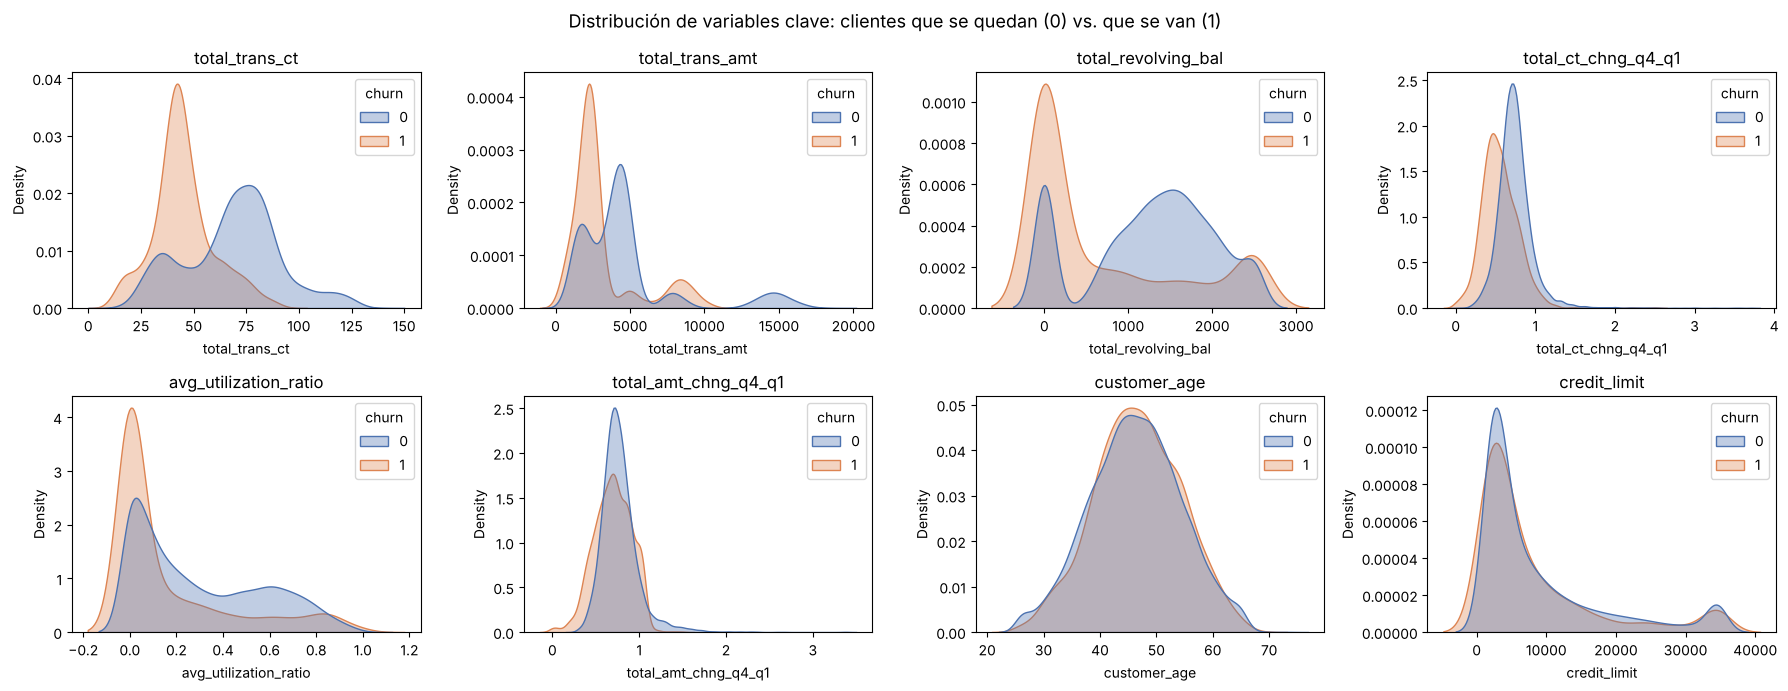

In [10]:
# Distribución de las variables más relevantes, separadas por churn
vars_clave = ["total_trans_ct", "total_trans_amt", "total_revolving_bal", "total_ct_chng_q4_q1",
              "avg_utilization_ratio", "total_amt_chng_q4_q1", "customer_age", "credit_limit"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), vars_clave):
    sns.kdeplot(data=df, x=col, hue="churn", common_norm=False, fill=True, alpha=0.35, ax=ax, palette=["#4C72B0", "#DD8452"])
    ax.set_title(col)
plt.suptitle("Distribución de variables clave: clientes que se quedan (0) vs. que se van (1)", fontsize=13)
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/eda_distribuciones.png", bbox_inches="tight"); plt.show()

* Los que se van hacen menos transacciones (43 vs 71), transan menos y su saldo rotativo es 0.
* Edad, antigüedad y cupo casi no cambian.

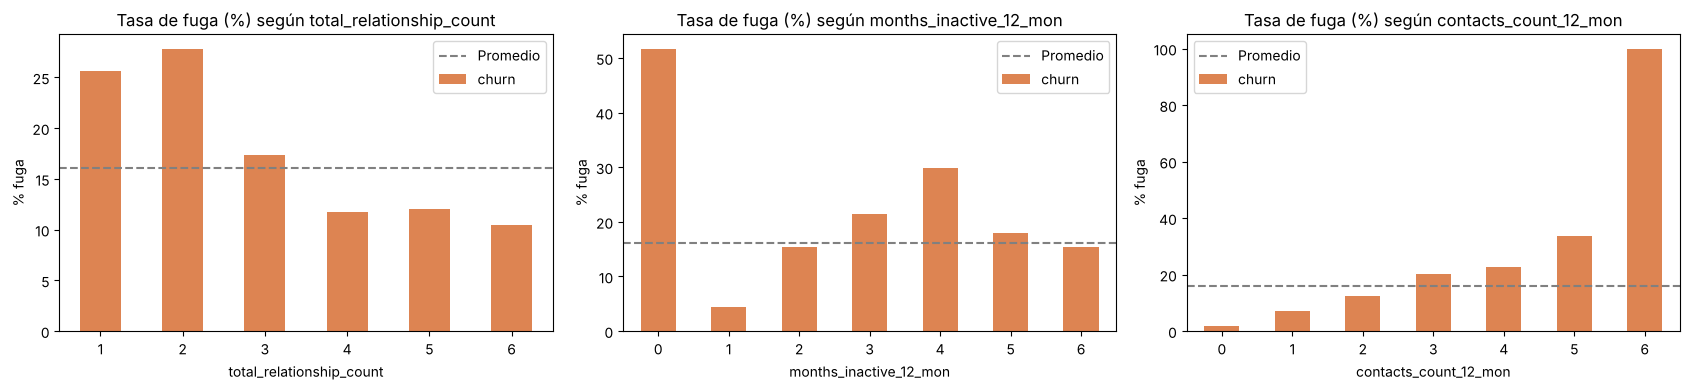

In [11]:
# Variables discretas de relación con el banco: tasa de fuga por valor
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ["total_relationship_count", "months_inactive_12_mon", "contacts_count_12_mon"]):
    tasa = df.groupby(col)["churn"].mean() * 100
    tasa.plot(kind="bar", ax=ax, color="#DD8452")
    ax.axhline(df["churn"].mean() * 100, color="gray", ls="--", label="Promedio")
    ax.set_title(f"Tasa de fuga (%) según {col}"); ax.set_ylabel("% fuga"); ax.tick_params(axis="x", rotation=0); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/eda_relacion_banco.png", bbox_inches="tight"); plt.show()

* 1–2 productos: ~27% de fuga vs ~11% con 4+.
* Con 6 contactos se fue el 100%. La inactividad también sube la fuga.

### 3.2 Variables categóricas

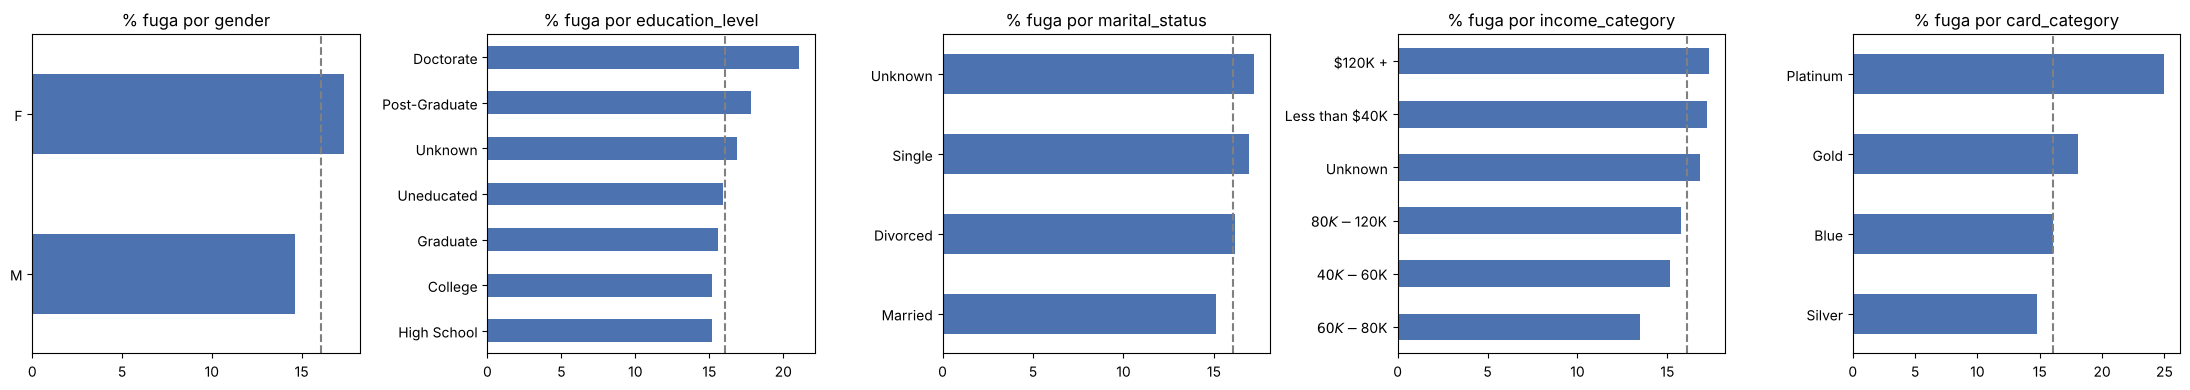

{'F': 5358, 'M': 4769}
{'Graduate': 3128, 'High School': 2013, 'Unknown': 1519, 'Uneducated': 1487, 'College': 1013, 'Post-Graduate': 516, 'Doctorate': 451}
{'Married': 4687, 'Single': 3943, 'Unknown': 749, 'Divorced': 748}
{'Less than $40K': 3561, '$40K - $60K': 1790, '$80K - $120K': 1535, '$60K - $80K': 1402, 'Unknown': 1112, '$120K +': 727}
{'Blue': 9436, 'Silver': 555, 'Gold': 116, 'Platinum': 20}


In [12]:
cat_cols = ["gender", "education_level", "marital_status", "income_category", "card_category"]
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, cat_cols):
    (df.groupby(col)["churn"].mean() * 100).sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
    ax.axvline(df["churn"].mean() * 100, color="gray", ls="--")
    ax.set_title(f"% fuga por {col}"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/eda_categoricas.png", bbox_inches="tight"); plt.show()

for col in cat_cols:
    print(df[col].value_counts().to_dict())

* La demografía diferencia poco (13%–21%). Gold y Platinum se agrupan por tener pocos clientes.

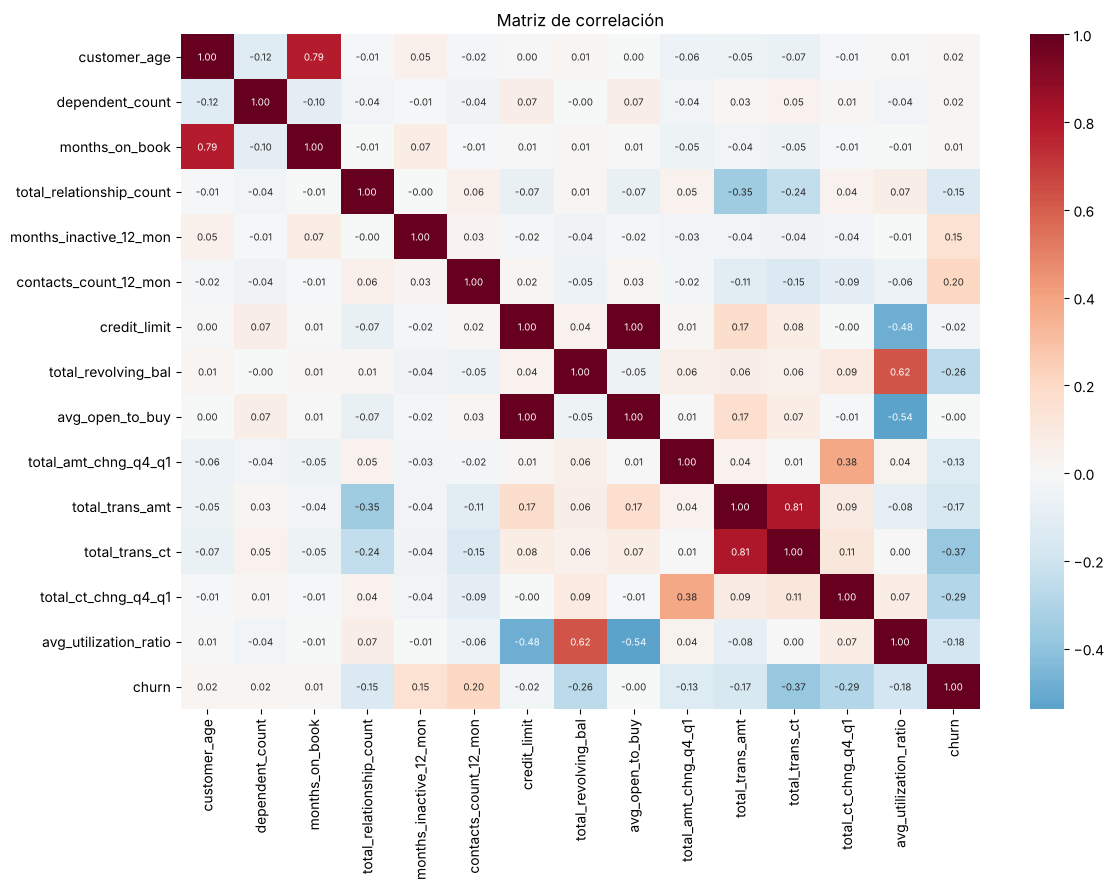

In [13]:
# Matriz de correlación de las variables numéricas
plt.figure(figsize=(12, 9))
sns.heatmap(df[num_cols + ["churn"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 7})
plt.title("Matriz de correlación"); plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/eda_correlacion.png", bbox_inches="tight"); plt.show()

* `credit_limit` y `avg_open_to_buy` tienen correlación ≈ 1 → se elimina `avg_open_to_buy`.

### 3.3 Pruebas estadísticas
Mann-Whitney U (numéricas) y chi-cuadrado con V de Cramér (categóricas).

In [14]:
from scipy.stats import mannwhitneyu, chi2_contingency

filas = []
for col in num_cols:
    a, b = df.loc[df["churn"] == 0, col], df.loc[df["churn"] == 1, col]
    p = mannwhitneyu(a, b).pvalue
    filas.append({"Variable": col, "Mediana se queda": a.median(), "Mediana se va": b.median(),
                  "p-valor": p, "Significativa al 5%": "Sí" if p < 0.05 else "No"})
pruebas_num = pd.DataFrame(filas).sort_values("p-valor")
pruebas_num.style.format({"p-valor": "{:.2e}", "Mediana se queda": "{:.2f}", "Mediana se va": "{:.2f}"})

,Variable,Mediana se queda,Mediana se va,p-valor,Significativa al 5%
11,total_trans_ct,71.00,43.00,0.00e+00,Sí
12,total_ct_chng_q4_q1,0.72,0.53,1.91e-216,Sí
7,total_revolving_bal,1364.00,0.00,1.92e-129,Sí
13,avg_utilization_ratio,0.21,0.00,2.87e-129,Sí
10,total_trans_amt,4100.00,2329.00,2.72e-112,Sí
5,contacts_count_12_mon,2.00,3.00,1.11e-80,Sí
4,months_inactive_12_mon,2.00,3.00,5.42e-67,Sí
3,total_relationship_count,4.00,3.00,2.91e-51,Sí
9,total_amt_chng_q4_q1,0.74,0.70,1.06e-24,Sí
6,credit_limit,4643.50,4178.00,3.01e-07,Sí


In [15]:
filas = []
for col in cat_cols:
    tabla = pd.crosstab(df[col], df["churn"])
    chi2, p, gl, _ = chi2_contingency(tabla)
    v_cramer = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    filas.append({"Variable": col, "Chi-cuadrado": chi2, "p-valor": p, "V de Cramér": v_cramer,
                  "Significativa al 5%": "Sí" if p < 0.05 else "No"})
pruebas_cat = pd.DataFrame(filas).sort_values("p-valor")
pruebas_cat.style.format({"Chi-cuadrado": "{:.1f}", "p-valor": "{:.4f}", "V de Cramér": "{:.3f}"})

,Variable,Chi-cuadrado,p-valor,V de Cramér,Significativa al 5%
0,gender,13.9,0.0002,0.037,Sí
3,income_category,12.8,0.0250,0.036,Sí
1,education_level,12.5,0.0515,0.035,No
2,marital_status,6.1,0.1089,0.024,No
4,card_category,2.2,0.5252,0.015,No


* Comportamiento y relación: todas significativas (p < 0,001). Edad y antigüedad no.
* Categóricas: solo género e ingresos son significativas, con asociación muy débil (V < 0,04).

### 3.4 Information Value (IV)
`WoE = ln(% se quedan / % se van)` · `IV = Σ (% se quedan − % se van) × WoE`

< 0,02 ninguno · 0,02–0,10 débil · 0,10–0,30 medio · 0,30–0,50 fuerte · > 0,50 muy fuerte

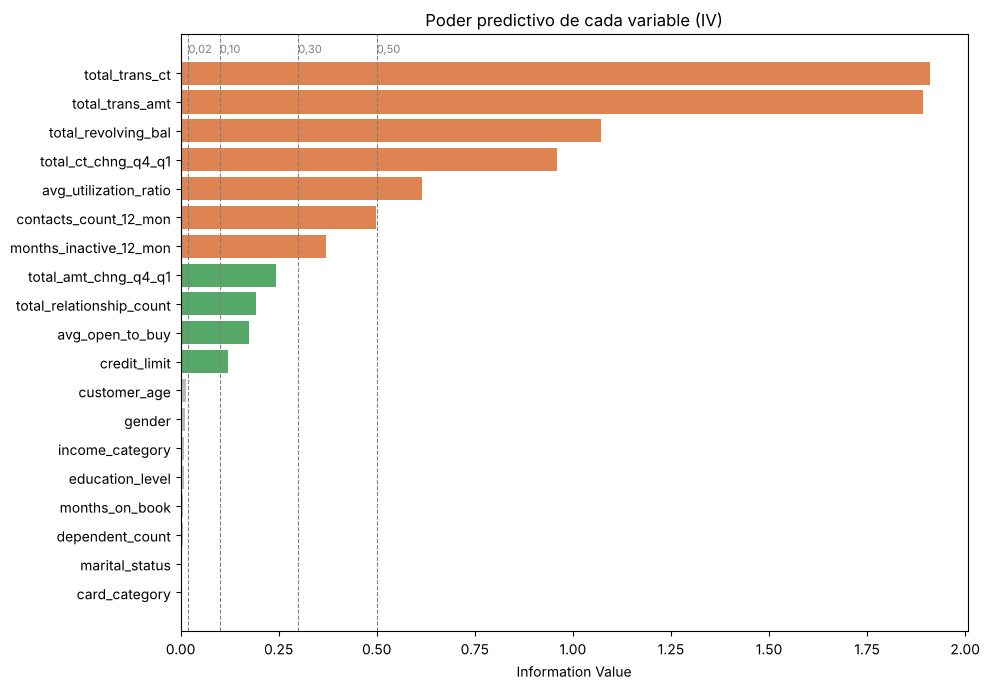

,Variable,IV,Poder predictivo
0,total_trans_ct,1.911,Muy fuerte
1,total_trans_amt,1.893,Muy fuerte
2,total_revolving_bal,1.072,Muy fuerte
3,total_ct_chng_q4_q1,0.959,Muy fuerte
4,avg_utilization_ratio,0.615,Muy fuerte
5,contacts_count_12_mon,0.498,Fuerte
6,months_inactive_12_mon,0.370,Fuerte
7,total_amt_chng_q4_q1,0.242,Medio
8,total_relationship_count,0.192,Medio
9,avg_open_to_buy,0.175,Medio


In [16]:
def information_value(data, col, objetivo="churn", tramos=10):
    x = data[col]
    if pd.api.types.is_numeric_dtype(x) and x.nunique() > tramos:
        x = pd.qcut(x, tramos, duplicates="drop")
    t = pd.crosstab(x, data[objetivo])
    se_quedan = (t[0] + 0.5) / t[0].sum()     # +0,5 evita divisiones por cero en tramos vacíos
    se_van = (t[1] + 0.5) / t[1].sum()
    woe = np.log(se_quedan / se_van)
    return float(((se_quedan - se_van) * woe).sum())

def clasificar_iv(v):
    return ("Ninguno" if v < 0.02 else "Débil" if v < 0.1 else "Medio" if v < 0.3
            else "Fuerte" if v < 0.5 else "Muy fuerte")

iv = pd.DataFrame({"Variable": num_cols + cat_cols})
iv["IV"] = [information_value(df, c) for c in iv["Variable"]]
iv["Poder predictivo"] = iv["IV"].apply(clasificar_iv)
iv = iv.sort_values("IV", ascending=False).reset_index(drop=True)

colores = iv["IV"].apply(lambda v: "#DD8452" if v >= 0.3 else "#55A868" if v >= 0.1 else "#4C72B0" if v >= 0.02 else "#BBBBBB")
plt.figure(figsize=(10, 7))
plt.barh(iv["Variable"][::-1], iv["IV"][::-1], color=colores[::-1])
for x0, txt in [(0.02, "0,02"), (0.1, "0,10"), (0.3, "0,30"), (0.5, "0,50")]:
    plt.axvline(x0, color="gray", ls="--", lw=0.8); plt.text(x0, len(iv) - 0.3, txt, fontsize=8, color="gray")
plt.xlabel("Information Value"); plt.title("Poder predictivo de cada variable (IV)")
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/eda_information_value.png", bbox_inches="tight"); plt.show()
iv.round(3)

* 7 variables con IV fuerte o muy fuerte, todas de comportamiento. Demográficas: IV < 0,02.
* IV > 0,5 es poco común → validar con un periodo posterior (out-of-time).

### 3.5 Tasa de fuga por deciles

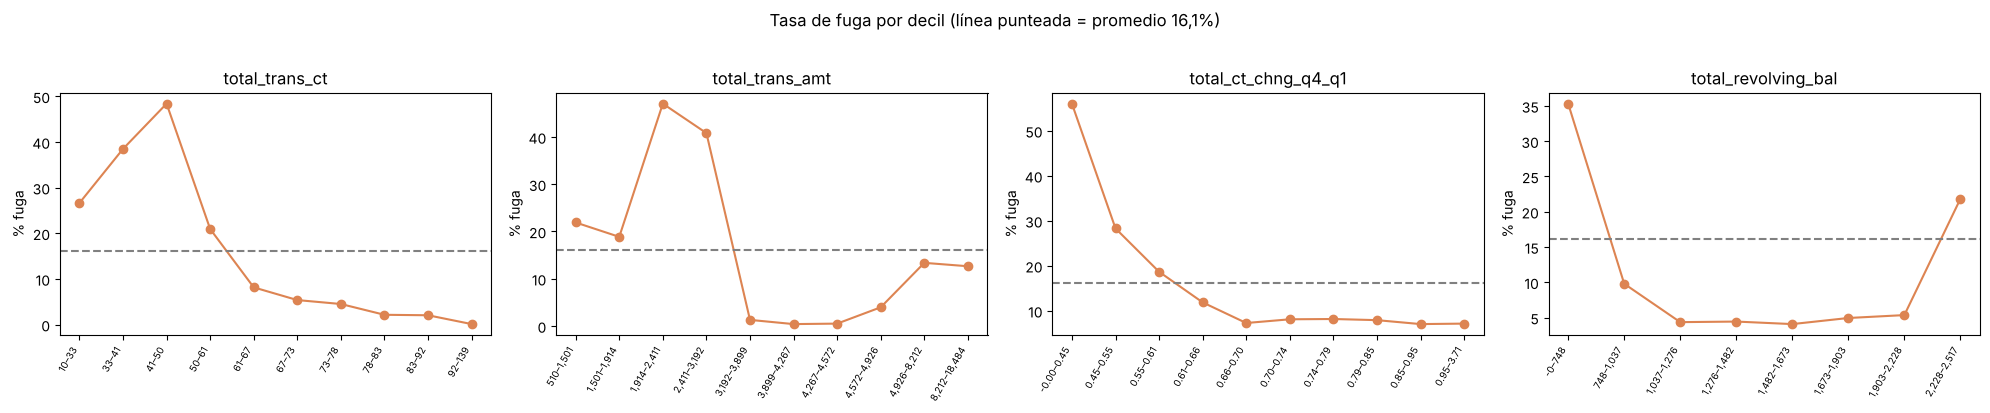

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ["total_trans_ct", "total_trans_amt", "total_ct_chng_q4_q1", "total_revolving_bal"]):
    tramos = pd.qcut(df[col], 10, duplicates="drop")
    tasa = df.groupby(tramos, observed=True)["churn"].mean() * 100
    etiquetas = [f"{iv_.left:,.0f}–{iv_.right:,.0f}" if df[col].max() > 10 else f"{iv_.left:.2f}–{iv_.right:.2f}" for iv_ in tasa.index]
    ax.plot(range(len(tasa)), tasa.values, marker="o", color="#DD8452")
    ax.axhline(df["churn"].mean() * 100, color="gray", ls="--")
    ax.set_xticks(range(len(tasa))); ax.set_xticklabels(etiquetas, rotation=60, ha="right", fontsize=7)
    ax.set_title(col); ax.set_ylabel("% fuga")
plt.suptitle("Tasa de fuga por decil (línea punteada = promedio 16,1%)", y=1.02)
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/eda_deciles.png", bbox_inches="tight"); plt.show()

* Máxima fuga entre 41 y 50 transacciones (48%): clientes que bajaron su actividad.
* Más de ~61 transacciones: menos de 10%. Caída Q4→Q1 bajo 0,45: 56%.

### 3.6 Interacciones

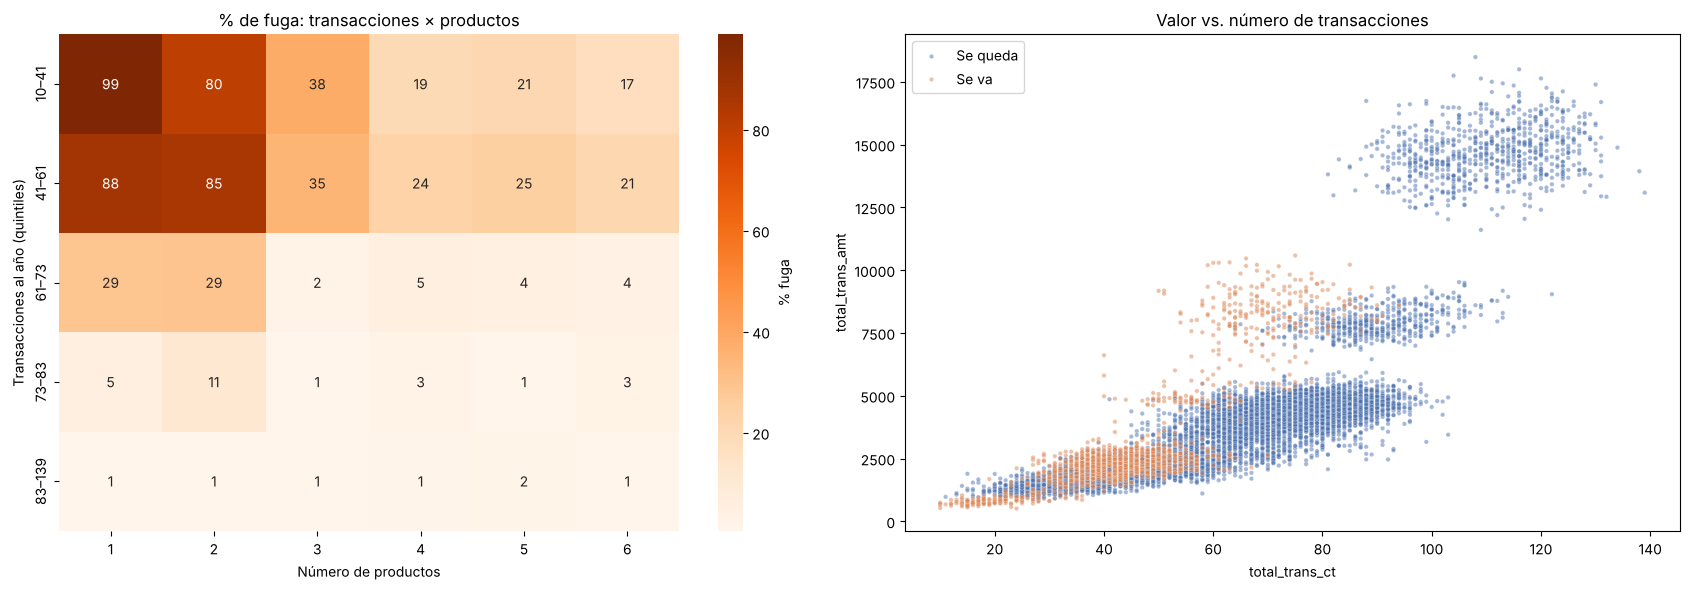

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
# Mapa de calor: tasa de fuga según transacciones (quintiles) y número de productos
tramos_ct = pd.qcut(df["total_trans_ct"], 5)
mapa = df.pivot_table(index=tramos_ct, columns="total_relationship_count", values="churn", aggfunc="mean", observed=True) * 100
mapa.index = [f"{i.left:.0f}–{i.right:.0f}" for i in mapa.index]
sns.heatmap(mapa, annot=True, fmt=".0f", cmap="Oranges", ax=axes[0], cbar_kws={"label": "% fuga"})
axes[0].set_xlabel("Número de productos"); axes[0].set_ylabel("Transacciones al año (quintiles)")
axes[0].set_title("% de fuga: transacciones × productos")
# Dispersión: valor vs. número de transacciones
sns.scatterplot(data=df.sample(frac=1, random_state=SEMILLA), x="total_trans_ct", y="total_trans_amt",
                hue=df["churn"].map({0: "Se queda", 1: "Se va"}), palette={"Se queda": "#4C72B0", "Se va": "#DD8452"},
                s=10, alpha=0.5, ax=axes[1])
axes[1].set_title("Valor vs. número de transacciones"); axes[1].legend(title="")
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/eda_interacciones.png", bbox_inches="tight"); plt.show()

* Menos de 61 transacciones y 1–2 productos → 80–99% de fuga; con 3+ productos baja a 17–38%.
* Se ven grupos por tramos → los árboles los capturan bien.

### 3.7 Valores atípicos (regla de Tukey)

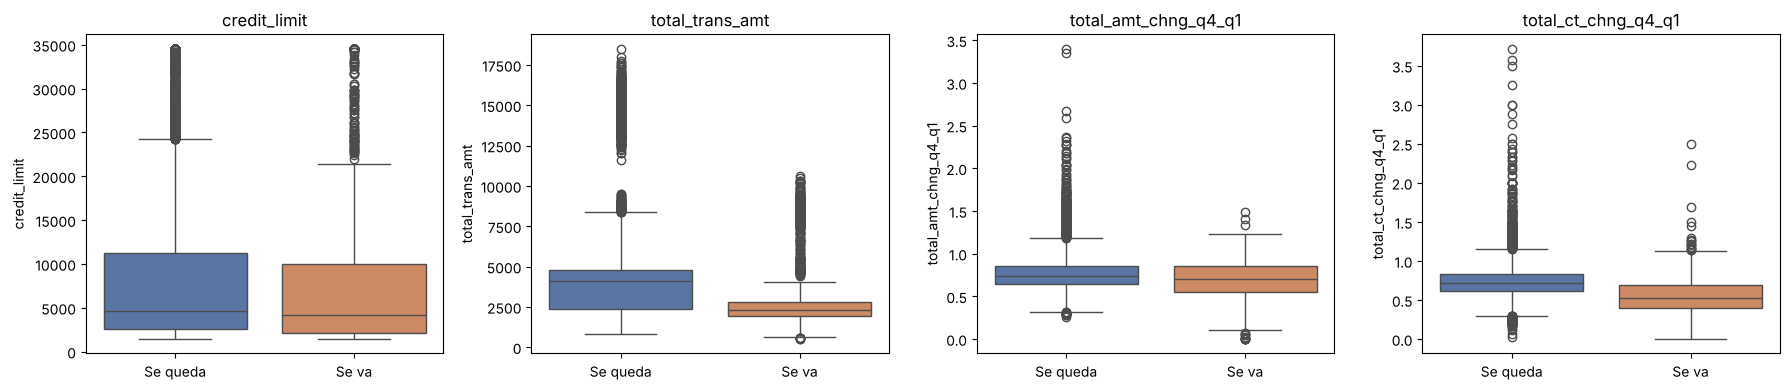

,Atípicos,% de clientes,% fuga en atípicos
credit_limit,984,9.7,16.1
avg_open_to_buy,963,9.5,16.8
total_trans_amt,896,8.8,9.8
contacts_count_12_mon,629,6.2,19.1
total_amt_chng_q4_q1,396,3.9,12.6
total_ct_chng_q4_q1,394,3.9,22.1
months_on_book,386,3.8,13.2
months_inactive_12_mon,331,3.3,19.9
customer_age,2,0.0,0.0
total_trans_ct,2,0.0,0.0


In [19]:
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
ric = q3 - q1
atipicos = ((df[num_cols] < q1 - 1.5 * ric) | (df[num_cols] > q3 + 1.5 * ric))
resumen_atipicos = pd.DataFrame({"Atípicos": atipicos.sum(), "% de clientes": atipicos.mean() * 100,
                                 "% fuga en atípicos": [df.loc[atipicos[c], "churn"].mean() * 100 if atipicos[c].any() else np.nan for c in num_cols]})
resumen_atipicos = resumen_atipicos[resumen_atipicos["Atípicos"] > 0].sort_values("Atípicos", ascending=False)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["credit_limit", "total_trans_amt", "total_amt_chng_q4_q1", "total_ct_chng_q4_q1"]):
    sns.boxplot(data=df, x=df["churn"].map({0: "Se queda", 1: "Se va"}), y=col, ax=ax, palette=["#4C72B0", "#DD8452"])
    ax.set_xlabel(""); ax.set_title(col)
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/eda_atipicos.png", bbox_inches="tight"); plt.show()
resumen_atipicos.round(1)

* Son clientes reales de alto cupo o alto uso, no errores → se conservan.

## 4. Preparación de datos
Variables nuevas, categorías raras, dummies y partición 80/20 estratificada. El escalado va dentro del Pipeline de cada modelo.

In [20]:
# Variables nuevas (feature engineering)
df["ticket_promedio"] = df["total_trans_amt"] / df["total_trans_ct"]          # valor promedio por transacción
df["trans_por_producto"] = df["total_trans_ct"] / df["total_relationship_count"]  # intensidad de uso por producto
df["inactivo_y_contactado"] = df["months_inactive_12_mon"] * df["contacts_count_12_mon"]  # interacción de alertas
df[["ticket_promedio", "trans_por_producto", "inactivo_y_contactado", "churn"]].groupby("churn").median()

,ticket_promedio,trans_por_producto,inactivo_y_contactado
churn,,,
0,55.920809,16.225000,4.0
1,54.954545,13.666667,8.0


In [21]:
# Función de clase: agrupar categorías con pocos datos
def CombineRareCategories(data, mincount):
    for col in data.columns:
        if data[col].dtype == object or str(data[col].dtype) in ("string", "str"):
            for category, count in data[col].value_counts().items():
                if count < mincount:
                    data[col] = data[col].replace(category, "Other_" + col)

ids = df["clientnum"]
df_modelo = df.drop(columns=["clientnum", "attrition_flag", "avg_open_to_buy"])
CombineRareCategories(df_modelo, 150)
df_modelo["card_category"].value_counts()

card_category
Blue                   9436
Silver                  555
Other_card_category     136
Name: count, dtype: int64

In [22]:
# Crear variables dummies (igual que en clase)
cat_cols = df_modelo.select_dtypes(exclude=["number"]).columns.tolist()
print("Variables categóricas:", cat_cols)
df_modelo = pd.get_dummies(df_modelo, columns=cat_cols, drop_first=True, dtype=int)
print(df_modelo.shape)
df_modelo.head()

Variables categóricas: ['gender', 'education_level', 'marital_status', 'income_category', 'card_category']
(10127, 34)


,customer_age,dependent_count,months_on_book,total_relationship_count,months_inactive_12_mon,contacts_count_12_mon,credit_limit,total_revolving_bal,total_amt_chng_q4_q1,total_trans_amt,total_trans_ct,total_ct_chng_q4_q1,avg_utilization_ratio,churn,ticket_promedio,trans_por_producto,inactivo_y_contactado,gender_M,education_level_Doctorate,education_level_Graduate,education_level_High School,education_level_Post-Graduate,education_level_Uneducated,education_level_Unknown,marital_status_Married,marital_status_Single,marital_status_Unknown,income_category_$40K - $60K,income_category_$60K - $80K,income_category_$80K - $120K,income_category_Less than $40K,income_category_Unknown,card_category_Other_card_category,card_category_Silver
0,45,3,39,5,1,3,12691.0,777,1.335,1144,42,1.625,0.061,0,27.238095,8.400000,3,1,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0
1,49,5,44,6,1,2,8256.0,864,1.541,1291,33,3.714,0.105,0,39.121212,5.500000,2,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0
2,51,3,36,4,1,0,3418.0,0,2.594,1887,20,2.333,0.000,0,94.350000,5.000000,0,1,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0
3,40,4,34,3,4,1,3313.0,2517,1.405,1171,20,2.333,0.760,0,58.550000,6.666667,4,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0
4,40,3,21,5,1,0,4716.0,0,2.175,816,28,2.500,0.000,0,29.142857,5.600000,0,1,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0


In [23]:
# Definir variable objetivo (y) y variables explicativas (X)
y = df_modelo["churn"]
X = df_modelo.drop(columns="churn")

# Dividir 80% entrenamiento y 20% test, estratificado por la variable objetivo
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, ids, test_size=0.20, stratify=y, random_state=SEMILLA)

print(X_train.shape, X_test.shape)
print("Tasa de fuga train: %.2f%% | test: %.2f%%" % (100 * y_train.mean(), 100 * y_test.mean()))

(8101, 33) (2026, 33)
Tasa de fuga train: 16.07% | test: 16.04%


In [24]:
# Guardar los datos preparados: TODOS los notebooks de modelos usarán exactamente esta partición
import pickle
datos = {"X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test,
         "id_train": id_train, "id_test": id_test, "columnas": X.columns.tolist(),
         "df_original": df}
with open(RUTA_DATOS_MODELO, "wb") as f:
    pickle.dump(datos, f)
print("Datos guardados en data/datos_modelo.pkl  ->  ahora puede ejecutar los notebooks 01 a 06")

Datos guardados en data/datos_modelo.pkl  ->  ahora puede ejecutar los notebooks 01 a 06


## Resumen
* Fuga de 16% → métrica principal AUC.
* Pruebas estadísticas e IV: el churn se explica por comportamiento, no por demografía.
* Segmento crítico: menos de 61 transacciones y 1–2 productos.
* Partición guardada en `data/datos_modelo.pkl` para todos los modelos.